# Student mental health data audit

## 1. Load the CSV

In [2]:
from pathlib import Path

import pandas as pd

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

csv_path = project_root / "data" / "student_mental_health.csv"
df = pd.read_csv(csv_path)

print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
df.dtypes.to_frame("dtype")

Rows: 2,000 | Columns: 17


,dtype
Student_ID,str
Age,int64
Gender,str
Year_of_Study,int64
Sleep_Hours,float64
Study_Hours_Per_Week,float64
GPA,float64
Social_Media_Hours,float64
Screen_Time_Hours,float64
Physical_Activity,str


## 2. Check data quality

Count missing values and duplicates, then look at the minimum and maximum of each numeric column.

In [3]:
missing = df.isna().sum()
display(missing[missing > 0].sort_values(ascending=False).to_frame("Missing values"))

print("Duplicate rows:", df.duplicated().sum())
print("Repeated student IDs:", df["Student_ID"].duplicated().sum())
print("Missing student IDs:", df["Student_ID"].isna().sum())
display(df.describe().round(2))

,Missing values
Financial_Stress,91
Diet_Quality,69
Sleep_Hours,62
Social_Media_Hours,58
Family_Support,54
Attendance_Rate,47
GPA,38


Duplicate rows: 0
Repeated student IDs: 0
Missing student IDs: 0


,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.00,2000.00,1938.00,2000.00,1962.00,1942.00,2000.00,1909.00,1946.00,1953.00
mean,21.13,2.63,6.76,20.00,2.56,6.01,8.55,5.96,6.52,85.08
std,2.14,1.32,1.13,5.72,0.34,1.15,1.66,1.89,1.84,7.22
min,17.00,1.00,3.30,2.40,1.50,2.10,3.30,1.40,1.70,54.40
25%,20.00,1.00,6.00,16.00,2.32,5.22,7.40,4.50,5.10,80.30
50%,21.00,2.00,6.70,19.80,2.56,6.00,8.50,6.10,6.70,85.10
75%,23.00,4.00,7.60,24.00,2.79,6.70,9.70,7.40,8.00,90.00
max,29.00,5.00,10.00,38.30,3.66,10.00,14.00,10.00,9.90,100.00


## 3. Check the target and set aside test rows

The [dataset guide](../data/README.md) explains each column. It says the risk labels are simulated from a weighted score that uses inputs such as sleep and financial stress. Use 80% of the rows for exploration and reserve 20% for final testing. Stratification keeps the class proportions similar in both groups.

In [4]:
from sklearn.model_selection import train_test_split

target = "Mental_Health_Risk"
display(df[target].value_counts(dropna=False).to_frame("Students"))

train_df, test_df = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df[target]
)
print("Training rows:", len(train_df))
print("Test rows:", len(test_df))

,Students
Mental_Health_Risk,
High,680
Medium,660
Low,660


Training rows: 1600
Test rows: 400


## 4. Draw box plots

The box shows the middle half of the values. Its width is the IQR. Points beyond the whiskers are worth checking.

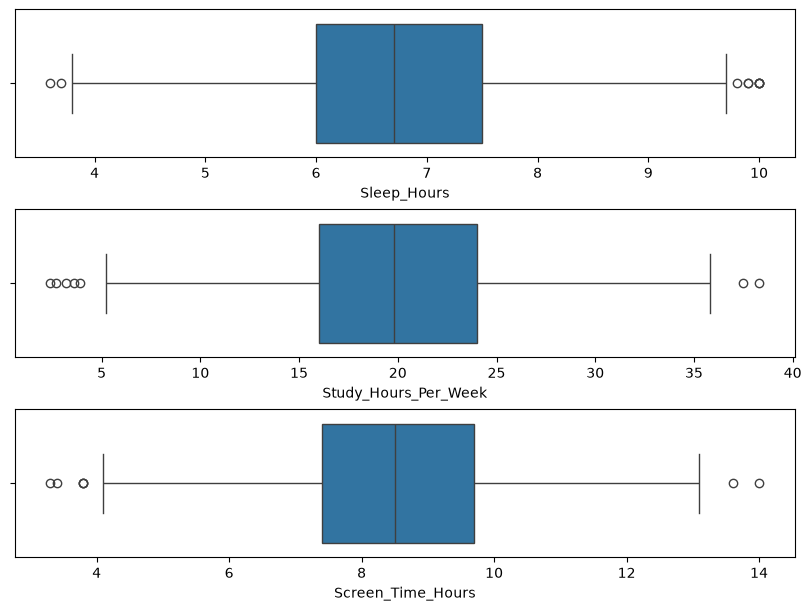

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(3, 1, figsize=(8, 6), layout="constrained")
sns.boxplot(data=train_df, x="Sleep_Hours", ax=axes[0])
sns.boxplot(data=train_df, x="Study_Hours_Per_Week", ax=axes[1])
sns.boxplot(data=train_df, x="Screen_Time_Hours", ax=axes[2])
plt.show()

## 5. Look for relationships

The heatmap shows which numeric features tend to move together. To check how each numeric feature moves with risk, give the ordered labels ranks from 0 to 2 and use Spearman correlation. The table at the end shows the risk percentages within each prior-history group.

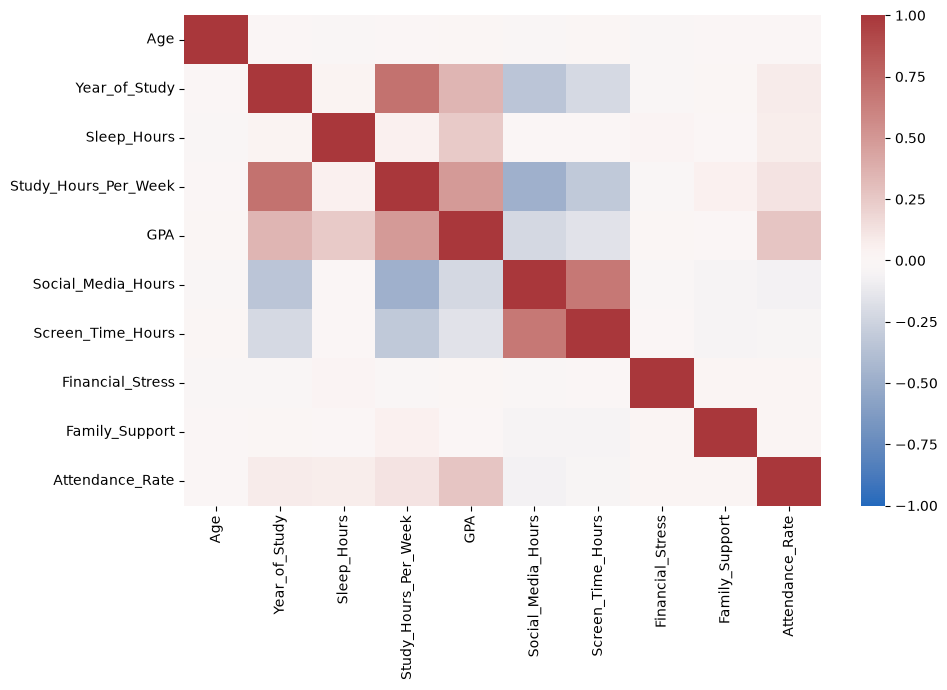

,Risk correlation
Sleep_Hours,-0.55
GPA,-0.35
Financial_Stress,0.31
Study_Hours_Per_Week,-0.26
Family_Support,-0.24
Social_Media_Hours,0.21
Screen_Time_Hours,0.18
Year_of_Study,-0.17
Attendance_Rate,-0.13
Age,0.00


Mental_Health_Risk,High,Low,Medium
Previous_Mental_Health_History,,,
No,28.2,38.7,33.1
Yes,48.3,18.9,32.8


In [6]:
numeric = train_df.select_dtypes(include="number")
plt.figure(figsize=(10, 7))
sns.heatmap(numeric.corr(method="spearman"), cmap="vlag", vmin=-1, vmax=1)
plt.tight_layout()
plt.show()

risk_rank = train_df[target].map({"Low": 0, "Medium": 1, "High": 2})
risk_correlation = numeric.corrwith(risk_rank, method="spearman")
display(risk_correlation.sort_values(key=abs, ascending=False).round(2).to_frame("Risk correlation"))

history = train_df["Previous_Mental_Health_History"]
display(pd.crosstab(history, train_df[target], normalize="index").mul(100).round(1))

## Day 1 notes

- The CSV has 2,000 rows and 17 columns. There are no duplicate rows or repeated student IDs. Financial stress has the most missing values (91 of 2,000).
- High accounts for 34% of rows. Medium and Low each account for 33%. Start without resampling.
- The guide gives an example minimum age of 18. The CSV includes age 17 and also has sleep and study-hour values outside the guide's example ranges. Review the flagged values before deciding whether to change them.
- Sleep hours have the strongest numeric relationship with the simulated risk labels in the training split. The guide lists sleep as an input to the label score, so that pattern is expected.
- On Day 2, reuse the split, exclude Student_ID from model inputs and fit the preprocessing on training data.

## Day 2 · Preprocessing

### 1. Split features and labels together

Use the same stratified 80/20 split as Day 1. Keep the target in y and drop Student_ID from the inputs because it only identifies a row.

In [18]:
X = df.drop(columns=["Student_ID", "Mental_Health_Risk"])
y = df["Mental_Health_Risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

### 2. Build the preprocessing pipeline

- **Numeric columns.** Fill blanks with the training median and standardize each column.
- **Categorical columns.** Fill blanks with the most frequent training category. One-hot encoding creates a separate indicator for each known category. An unseen category gets zeros in the indicators for that column.
- **Outliers and class balance.** Keep the plausible values flagged on Day 1. The classes are already close in size, so skip resampling.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_columns = X_train.select_dtypes(include="number").columns
categorical_columns = X_train.select_dtypes(exclude="number").columns

numeric_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns),
])

### 3. Check that the pipeline works

Fit learns the fill values, scaling statistics and categories from X_train. Transform applies those settings to X_test. On Day 3, put the preprocessor and the classifier in one pipeline and give cross-validation the original X_train. Each fold will learn its preprocessing from its own training rows.

In [8]:
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Prepared training shape:", X_train_prepared.shape)
print("Prepared test shape:", X_test_prepared.shape)

Prepared training shape: (1600, 23)
Prepared test shape: (400, 23)


## Days 3–4 · Compare and tune classifiers

Each grid starts with the classifier’s default value. This gives us the default and tuned scores from the same search. All models use the same five stratified training folds. Macro F1 gives Low, Medium, and High equal weight.

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score

classifiers = {
    "Logistic regression": LogisticRegression(max_iter=1000),
    "Random forest": RandomForestClassifier(random_state=42),
    "Gradient boosting": GradientBoostingClassifier(random_state=42),
}
param_grids = {
    "Logistic regression": {"classifier__C": [1.0, 0.1, 10.0]},
    "Random forest": {"classifier__max_depth": [None, 5, 10]},
    "Gradient boosting": {"classifier__learning_rate": [0.1, 0.05, 0.2]},
}

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
baseline = DummyClassifier(strategy="most_frequent")
baseline_scores = cross_val_score(baseline, X_train, y_train, cv=folds, scoring="f1_macro")
print(f"Dummy baseline macro F1: {baseline_scores.mean():.3f}")

Dummy baseline macro F1: 0.169


### 1. Run the searches

The double underscore in classifier__max_depth tells GridSearchCV to set max_depth on the step named classifier. Pass the raw X_train so each fold fits its own preprocessing. Use refit=False here so only the overall winner gets fitted on all the training rows.

In [10]:
searches = {}
results = []

for name, classifier in classifiers.items():
    model = Pipeline([
        ("preprocess", preprocessor),
        ("classifier", classifier),
    ])
    search = GridSearchCV(
        model, param_grids[name], cv=folds, scoring="f1_macro",
        refit=False, error_score="raise",
    )
    search.fit(X_train, y_train)
    searches[name] = search

    results.append({
        "Classifier": name,
        "Default macro F1": search.cv_results_["mean_test_score"][0],
        "Best macro F1": search.best_score_,
        "Best F1 std": search.cv_results_["std_test_score"][search.best_index_],
        "Best settings": search.best_params_,
    })

comparison = pd.DataFrame(results).set_index("Classifier")
comparison = comparison.sort_values("Best macro F1", ascending=False)
display(comparison.round(3))

,Default macro F1,Best macro F1,Best F1 std,Best settings
Classifier,,,,
Logistic regression,0.747,0.750,0.019,{'classifier__C': 10.0}
Gradient boosting,0.686,0.686,0.013,{'classifier__learning_rate': 0.1}
Random forest,0.669,0.669,0.031,{'classifier__max_depth': None}


### 2. Evaluate the winner on the reserved test set

Choose the model by its training-fold score. Fit it on all 1,600 training rows, then use the 400 reserved rows to measure final performance.

Selected classifier: Logistic regression


,Test score
accuracy,0.752
macro_precision,0.752
macro_recall,0.752
macro_f1,0.752
macro_roc_auc,0.914


,precision,recall,f1-score,support
Low,0.815,0.803,0.809,132.0
Medium,0.629,0.629,0.629,132.0
High,0.812,0.824,0.818,136.0


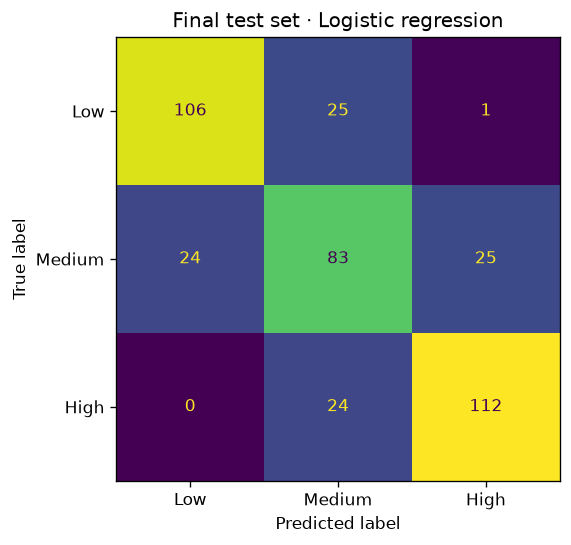

In [11]:
from sklearn.base import clone
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report,
    confusion_matrix, roc_auc_score,
)

winner = comparison.index[0]
winning_search = searches[winner]
final_model = clone(winning_search.estimator).set_params(**winning_search.best_params_)
final_model.fit(X_train, y_train)

predictions = final_model.predict(X_test)
probabilities = final_model.predict_proba(X_test)
labels = ["Low", "Medium", "High"]
report = classification_report(
    y_test, predictions, labels=labels, output_dict=True, zero_division=0
)
matrix = confusion_matrix(y_test, predictions, labels=labels)
test_scores = {
    "accuracy": accuracy_score(y_test, predictions),
    "macro_precision": report["macro avg"]["precision"],
    "macro_recall": report["macro avg"]["recall"],
    "macro_f1": report["macro avg"]["f1-score"],
    "macro_roc_auc": roc_auc_score(
        y_test, probabilities, labels=final_model.classes_, multi_class="ovr",
    ),
}
print("Selected classifier:", winner)
display(pd.Series(test_scores, name="Test score").round(3).to_frame())
display(pd.DataFrame(report).T.loc[labels].round(3))

ConfusionMatrixDisplay(matrix, display_labels=labels).plot(colorbar=False)
plt.title(f"Final test set · {winner}")
plt.show()

### 3. Save the pipeline and evaluation

The full pipeline accepts raw feature columns and includes the fitted scaler. Save the scaler separately for the project deliverable and export the evaluation for Streamlit.

In [12]:
import json

import joblib

models_dir = project_root / "models"
models_dir.mkdir(exist_ok=True)

pipeline_path = models_dir / "mental_health_pipeline.joblib"
scaler = final_model.named_steps["preprocess"].named_transformers_["numeric"].named_steps["scale"]
joblib.dump(final_model, pipeline_path)
joblib.dump(scaler, models_dir / "numeric_scaler.joblib")

evaluation = {
    "classifier": winner,
    "best_params": winning_search.best_params_,
    "cv_macro_f1": winning_search.best_score_,
    "test_scores": test_scores,
    "class_report": report,
    "labels": labels,
    "confusion_matrix": matrix.tolist(),
}
(models_dir / "evaluation.json").write_text(json.dumps(evaluation, indent=2), encoding="utf-8")

example = X_test.iloc[[0]]
reloaded = joblib.load(pipeline_path)
assert reloaded.predict(example)[0] == final_model.predict(example)[0]
print("Saved the pipeline, scaler, and evaluation. Reloaded prediction matches.")

Saved the pipeline, scaler, and evaluation. Reloaded prediction matches.


### What the test results show

Logistic regression had the highest cross-validation macro F1 (0.750). Its test macro F1 was 0.752. Medium was the hardest class to recover, with 62.9% recall. Of the actual Medium rows, the model misclassified 24 as Low, 25 as High. These results measure performance on simulated labels from this dataset.